# Do the five neighbourhood groups change with the 2026 mayoral result?

A quick exploratory re-run of the Model 8F clustering (`02_model_exploration.ipynb`) with a fourth election block added: the **2026 mayoral election** (Chow, Bradford, Other).

**Setup**
- Same 19 variables as Model 8F (2023 mayoral, 2025 provincial, 2025 federal) plus three 2026 shares: Chow, Bradford, Other. There is no 2026 turnout, because tract-level ballots cast are allocation noise (see `election_2026/01_election_demographic_exploration.ipynb`).
- **Equal block weights:** each election is standardized and divided by √(its variable count), so the four elections carry equal variance. 2026 has 3 variables, so each is divided by √3.
- **50/50 city/ward blend:** the city-relative and ward-relative versions are block-weighted separately, then combined 50/50. As in Model 8F, ward benchmarks are vote-weighted. The 2023 and 2026 mayoral blocks use the 25 wards, provincial uses ridings and federal uses the 2025 districts.
- PCA to ≥90% variance, then k-means with k=5, 30 inits, seed 42. The two anomalous tracts are left out of the fit and assigned to the nearest centre.
- 2026 shares are **mapped poll votes** only (about 76% of official votes have a polygon), interpolated to 2021 census tracts.

Section 1 first reproduces the original Model 8F labels, to check that this pipeline matches the published one.

In [1]:
import warnings
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

ROOT = Path("../..")
CLUSTER_DIR = ROOT / "data/clustering_neighbourhoods"
MAYOR_GPKG = ROOT / "data/election_results/2026-results-clean/mayor_2023_2026_ct.gpkg"
MAP_DIR = ROOT / "analysis/toronto_election_turnout/data/archive/interpolation/map"

K, SEED, ALPHA = 5, 42, 0.5
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4"]   # Model 8F groups, in OLD_ORDER (palette slots 1-5)
# new groups keep the colour of the Model 8F group they continue; group 5 (Bradford-Conservative Suburbs) gets a new hue (palette slot 7)
# and group 4 (Mixed Swing Suburbs) takes over the Suburban Conservatives yellow
CAT_NEW = ["#2a78d6", "#eb6834", "#e87ba4", "#eda100", "#6250d6"]
DIV = LinearSegmentedColormap.from_list("div", ["#eb6834", "#f0efec", "#2a78d6"])

/home/aniket/.local/lib/python3.10/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


## 1. Data and feature construction

In [2]:
base = pd.read_csv(CLUSTER_DIR / "profiles/ct_model_8f.csv")           # Model 8F inputs, residuals and labels
base["ctuid"] = base["ct_id"].map(lambda x: f"{x:.2f}")
mayor = gpd.read_file(MAYOR_GPKG, layer="mayor_ct").rename(columns={"ctuid2021": "ctuid"})
vals = pd.read_csv(CLUSTER_DIR / "processed_clusters/ct_values.csv")       # tract demographics used in notebook 04

df = base.merge(mayor.drop(columns="geometry"), on="ctuid", how="left", validate="1:1")
assert len(df) == 585 and df["mayor2026_votes_candidates"].notna().all()
gdf = gpd.GeoDataFrame(df.merge(mayor[["ctuid", "geometry"]], on="ctuid"), geometry="geometry", crs=mayor.crs).to_crs(32617)

# existing three elections
OLD = ["mun_turnout", "mun_chow", "mun_bailao", "mun_saunders", "mun_furey", "mun_matlow", "mun_other",
       "prov_turnout", "prov_pc", "prov_ndp", "prov_liberal", "prov_green", "prov_other",
       "fed_turnout", "fed_liberal", "fed_conservative", "fed_ndp", "fed_green", "fed_other"]
# new 2026 mayoral block
NEW = {"m26_chow": "mayor2026_chow_olivia_pct", "m26_bradford": "mayor2026_bradford_brad_pct", "m26_other": "mayor2026_other_pct"}
for new, src in NEW.items():
    gdf[new] = gdf[src]
M26 = list(NEW)
print("2026 shares sum to 1:", np.allclose(gdf[M26].sum(axis=1), 1))

# 2026 city- and ward-relative deviations (vote-weighted, same recipe as the other blocks)
w = gdf["mayor2026_votes_candidates"]
for c in M26:
    gdf[f"{c}_vs_city"] = gdf[c] - (gdf[c] * w).sum() / w.sum()
    ward = (gdf[c] * w).groupby(gdf["mun_riding"]).transform("sum") / w.groupby(gdf["mun_riding"]).transform("sum")
    gdf[f"{c}_vs_riding"] = gdf[c] - ward

anomalous = gdf["is_anomalous"].astype(bool).values
print(f"{len(gdf)} tracts, {anomalous.sum()} anomalous (left out of the k-means fit)")

2026 shares sum to 1: True
585 tracts, 2 anomalous (left out of the k-means fit)


In [3]:
def run_model(blocks, k=K, alpha=ALPHA):
    '''blocks: {name: [columns]}. Block-weight the city- and ward-relative halves separately, blend, PCA >=90%, k-means.'''
    cols = [c for b in blocks.values() for c in b]
    halves = []
    for suffix, weight in (("_vs_city", alpha), ("_vs_riding", 1 - alpha)):
        X = gdf[[c + suffix for c in cols]].values.astype(float)
        out = np.zeros_like(X)
        for b in blocks.values():
            idx = [cols.index(c) for c in b]
            out[:, idx] = StandardScaler().fit_transform(X[:, idx]) / np.sqrt(len(idx))
        halves.append(weight * out)
    Xb = np.hstack(halves)
    n90 = int(np.searchsorted(np.cumsum(PCA().fit(Xb).explained_variance_ratio_), 0.90)) + 1
    Xp = PCA(n_components=n90, random_state=SEED).fit_transform(Xb)
    km = KMeans(n_clusters=k, n_init=30, random_state=SEED).fit(Xp[~anomalous])
    return km.predict(Xp), n90

BLOCKS_OLD = {"mayor 2023": OLD[:7], "provincial 2025": OLD[7:13], "federal 2025": OLD[13:]}
BLOCKS_NEW = {**BLOCKS_OLD, "mayor 2026": M26}

# sanity check: the pipeline reproduces the published Model 8F labels
chk, n = run_model(BLOCKS_OLD)
print(f"Reproduction of Model 8F (3 blocks): {n} PCs, ARI vs saved cluster_8f labels = {adjusted_rand_score(base['cluster_8f'], chk):.3f}")

lab, n = run_model(BLOCKS_NEW)
print(f"With 2026 block (4 blocks): {n} PCs; ARI vs Model 8F = {adjusted_rand_score(base['cluster_8f'], lab):.3f}")

Reproduction of Model 8F (3 blocks): 14 PCs, ARI vs saved cluster_8f labels = 1.000
With 2026 block (4 blocks): 14 PCs; ARI vs Model 8F = 0.441


## 2. Cluster maps

In [4]:
# --- helper weights: valid votes (shares) and citizens 18+ (turnout) from the interpolation files
def wts(fname, prefix):
    g = gpd.read_file(MAP_DIR / fname, ignore_geometry=True).set_index("ct_id")
    return g.loc[gdf["ctuid"], ["estimated_valid_candidate_votes", "citizen_canadian_18over"]].set_axis([f"{prefix}_votes", f"{prefix}_cit"], axis=1).reset_index(drop=True)
for f, p in [("municipal_2023_mayor_ct_map.geojson", "mun"), ("provincial_2025_ct_map.geojson", "prov"), ("federal_2025_ct_map.geojson", "fed")]:
    gdf[[f"{p}_votes", f"{p}_cit"]] = wts(f, p)
gdf["m26_votes"] = gdf["mayor2026_votes_candidates"]

# --- order new clusters by pooled 2026 Chow share (high to low) so group 1 is the most Chow-leaning
gdf["new_raw"] = lab
order = (gdf.groupby("new_raw").apply(lambda d: np.average(d["m26_chow"], weights=d["m26_votes"])).sort_values(ascending=False).index)
gdf["new"] = gdf["new_raw"].map({old: i for i, old in enumerate(order)})
# provisional names, read off the profiles in sections 3-4 (groups are ordered by pooled 2026 Chow share)
NAMES = {0: "1 Progressive Core", 1: "2 Soft-Left Belt", 2: "3 Low-turnout Diverse Suburbs", 3: "4 Mixed Swing Suburbs", 4: "5 Bradford-Conservative Suburbs"}

OLD_NAMES = {1: "Progressive Core", 2: "Soft-Left Belt", 3: "Civic Liberals", 0: "Suburban Conservatives", 4: "Low-turnout Suburbanites"}
OLD_ORDER = [1, 2, 3, 0, 4]

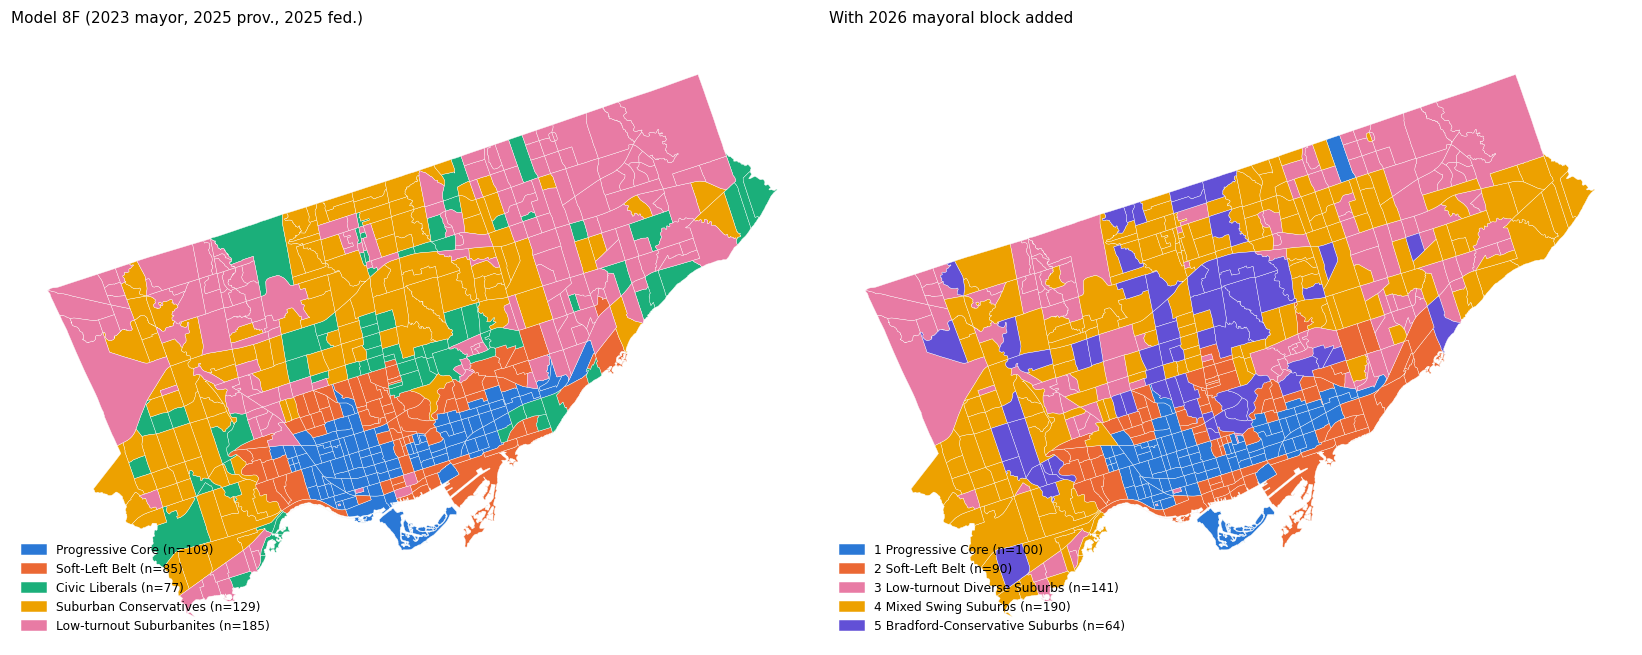

In [5]:
def draw(ax, col, order, names, colours, title):
    for i, key in enumerate(order):
        gdf[gdf[col] == key].plot(ax=ax, color=colours[i], edgecolor="#fcfcfb", linewidth=0.25)
    ax.set_axis_off(); ax.set_title(title, loc="left", fontsize=10)
    n = gdf[col].value_counts()
    ax.legend(handles=[Patch(color=colours[i], label=f"{names[k]} (n={n.get(k, 0)})") for i, k in enumerate(order)], loc="lower left", frameon=False, fontsize=8)

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
draw(axes[0], "cluster_8f", OLD_ORDER, OLD_NAMES, CAT, "Model 8F (2023 mayor, 2025 prov., 2025 fed.)")
draw(axes[1], "new", list(range(K)), NAMES, CAT_NEW, "With 2026 mayoral block added")
plt.tight_layout(); plt.show()

new,1 Progressive Core,2 Soft-Left Belt,3 Low-turnout Diverse Suburbs,4 Mixed Swing Suburbs,5 Bradford-Conservative Suburbs
cluster_8f,,,,,
Progressive Core,97,9,3,0,0
Soft-Left Belt,1,67,1,0,16
Civic Liberals,2,10,14,49,2
Suburban Conservatives,0,0,2,81,46
Low-turnout Suburbanites,0,4,121,60,0


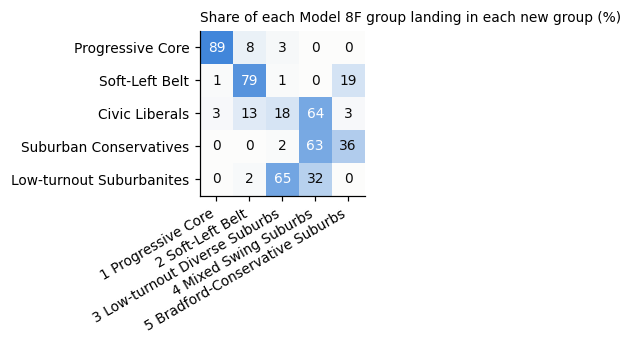

In [6]:
# how the old groups map onto the new ones (row %: where each old group's tracts ended up)
ct = pd.crosstab(gdf["cluster_8f"].map(OLD_NAMES), gdf["new"].map(NAMES)).reindex([OLD_NAMES[k] for k in OLD_ORDER])
display(ct)
fig, ax = plt.subplots(figsize=(6, 3.2))
pct = ct.div(ct.sum(axis=1), axis=0) * 100
im = ax.imshow(pct.values, cmap=LinearSegmentedColormap.from_list("seq", ["#fcfcfb", "#2a78d6"]), vmin=0, vmax=100)
ax.set_xticks(range(K), pct.columns, rotation=30, ha="right"); ax.set_yticks(range(K), pct.index)
for (i, j), v in np.ndenumerate(pct.values): ax.text(j, i, f"{v:.0f}", ha="center", va="center", color="white" if v > 55 else "#0b0b0b")
ax.set_title("Share of each Model 8F group landing in each new group (%)", loc="left", fontsize=9)
plt.tight_layout(); plt.show()

## 3. Political profile of the new groups

In [7]:
def pooled(d, cols, wcol):
    ok = d[wcol].notna()   # a few tracts lack a citizens-18+ weight, so their turnout is skipped
    return pd.Series({c: np.average(d.loc[ok & d[c].notna(), c], weights=d.loc[ok & d[c].notna(), wcol]) * 100 for c in cols})

POL = [("Chow 2023", "mun_chow", "mun_votes"), ("Bailão 2023", "mun_bailao", "mun_votes"), ("Mayor turnout 2023", "mun_turnout", "mun_cit"),
       ("Chow 2026", "m26_chow", "m26_votes"), ("Bradford 2026", "m26_bradford", "m26_votes"), ("Other 2026", "m26_other", "m26_votes"),
       ("Prov PC", "prov_pc", "prov_votes"), ("Prov NDP", "prov_ndp", "prov_votes"), ("Prov Lib", "prov_liberal", "prov_votes"), ("Prov turnout", "prov_turnout", "prov_cit"),
       ("Fed Lib", "fed_liberal", "fed_votes"), ("Fed CPC", "fed_conservative", "fed_votes"), ("Fed NDP", "fed_ndp", "fed_votes"), ("Fed turnout", "fed_turnout", "fed_cit")]

def political_table(col, order, names, pol=None):
    pol = pol or POL
    rows = {names[k]: pd.Series({lab_: pooled(gdf[gdf[col] == k], [c], w)[c] for lab_, c, w in pol}) for k in order}
    rows["Toronto"] = pd.Series({lab_: pooled(gdf, [c], w)[c] for lab_, c, w in pol})
    t = pd.DataFrame(rows).T
    t.insert(3, "Chow lead 2026", t["Chow 2026"] - t["Bradford 2026"])
    return t

pol_new = political_table("new", range(K), NAMES)
display(pol_new.round(1))

,Chow 2023,Bailão 2023,Mayor turnout 2023,Chow lead 2026,Chow 2026,Bradford 2026,Other 2026,Prov PC,Prov NDP,Prov Lib,Prov turnout,Fed Lib,Fed CPC,Fed NDP,Fed turnout
1 Progressive Core,53.5,22.8,45.7,48.9,72.7,23.7,3.6,15.3,51.1,29.2,54.3,62.7,20.3,14.9,74.1
2 Soft-Left Belt,41.0,30.1,44.3,25.4,61.1,35.7,3.2,22.7,36.7,36.8,51.4,62.1,27.5,8.6,75.9
3 Low-turnout Diverse Suburbs,37.4,27.2,29.7,18.7,55.4,36.7,7.9,41.6,14.5,39.8,41.3,59.7,34.8,4.0,65.4
4 Mixed Swing Suburbs,29.4,37.8,37.2,-3.9,45.8,49.6,4.6,43.8,7.5,43.6,46.6,54.8,41.3,3.0,69.5
5 Bradford-Conservative Suburbs,23.3,46.8,43.0,-26.2,35.2,61.4,3.3,44.3,12.8,39.2,47.8,52.4,43.5,3.0,70.2
Toronto,37.2,32.5,38.7,14.1,54.7,40.6,4.6,34.0,23.3,38.4,47.6,58.4,33.8,6.4,70.5


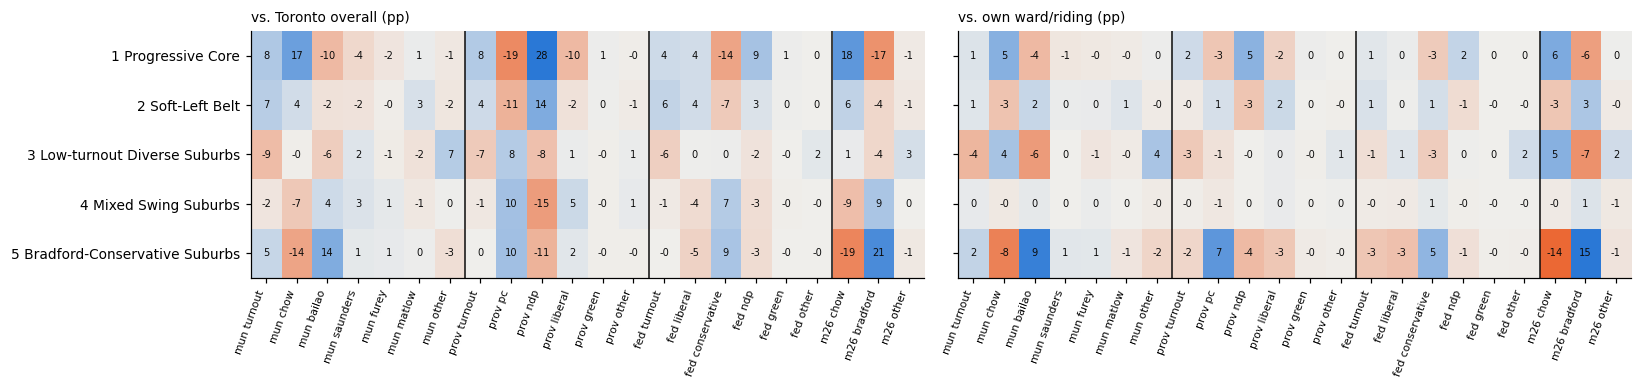

In [8]:
# city-relative and ward-relative profile (pp), pooled by group; the model's own inputs
PROFILE = OLD + M26
LABEL = {c: c.replace("_", " ") for c in PROFILE}
fig, axes = plt.subplots(1, 2, figsize=(15, 3.6), sharey=True)
for ax, suffix, title, vmax in [(axes[0], "_vs_city", "vs. Toronto overall (pp)", 25), (axes[1], "_vs_riding", "vs. own ward/riding (pp)", 10)]:
    prof = pd.DataFrame({c: [gdf.loc[gdf["new"] == k, c + suffix].mean() * 100 for k in range(K)] for c in PROFILE}, index=[NAMES[k] for k in range(K)])
    ax.imshow(prof.values, cmap=DIV, vmin=-vmax, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(PROFILE)), [LABEL[c] for c in PROFILE], rotation=70, ha="right", fontsize=7); ax.set_yticks(range(K), prof.index)
    for (i, j), v in np.ndenumerate(prof.values): ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=6.5, color="#0b0b0b")
    for x in (6.5, 12.5, 18.5): ax.axvline(x, color="#0b0b0b", lw=1)
    ax.set_title(title, loc="left", fontsize=9)
plt.tight_layout(); plt.show()

## 4. Demographic profile of the new groups

In [9]:
gdf = gdf.merge(vals[["ct_id", "population", "income_median", "avg_age", "avg_household_size", "pct_shelter_burdened_30plus", "pct_migrant_5yr"]], on="ct_id", how="left")
RATIOS = {"Renter households %": ("hhtnrent_abs", "den_hhtn_tot"), "Apartment dwellings %": ("dwtpapt__abs", "den_dwtp_tot"),
          "Visible minority %": ("vminvisi_abs", "den_vmin_tot"), "Immigrants %": ("imstimmi_abs", "den_imst_tot"),
          "University degree %": ("edcauniv_abs", "den_edca_tot"), "Age 65+ %": ("agec065p_abs", "den_agec_tot"),
          "Car commute %": ("jwmdauto_abs", "den_jwmd_tot"), "Transit commute %": ("jwmdtran_abs", "den_jwmd_tot")}
POPW = {"Median income ($)": "income_median", "Avg age": "avg_age", "Avg HH size": "avg_household_size", "Shelter burden %": "pct_shelter_burdened_30plus", "Recent migrants %": "pct_migrant_5yr"}

def demo_table(col, order, names):
    def one(d):
        r = {"CTs": len(d), "Population": d["population"].sum(), "Density /km²": d["population"].sum() / (d.geometry.area.sum() / 1e6)}
        r.update({k: d[a].sum() / d[b].sum() * 100 for k, (a, b) in RATIOS.items()})
        r.update({k: np.average(d[c].fillna(d[c].mean()), weights=d["population"]) for k, c in POPW.items()})
        return pd.Series(r)
    t = pd.DataFrame({names[k]: one(gdf[gdf[col] == k]) for k in order}).T
    t.loc["Toronto"] = one(gdf)
    t.insert(2, "Pop share %", t["Population"] / t.loc["Toronto", "Population"] * 100)
    return t

demo_new = demo_table("new", range(K), NAMES)
display(demo_new.round(1))

,CTs,Population,Pop share %,Density /km²,Renter households %,Apartment dwellings %,Visible minority %,Immigrants %,University degree %,Age 65+ %,Car commute %,Transit commute %,Median income ($),Avg age,Avg HH size,Shelter burden %,Recent migrants %
1 Progressive Core,100.0,437675.0,15.7,9290.1,59.5,72.4,41.1,35.1,47.1,13.9,40.5,30.8,43195.1,40.6,2.1,33.4,17.9
2 Soft-Left Belt,90.0,468531.0,16.8,6810.9,52.8,73.1,39.8,35.8,54.1,14.7,49.1,27.0,52771.1,40.6,2.0,34.2,22.7
3 Low-turnout Diverse Suburbs,141.0,701082.0,25.1,3887.0,52.0,62.3,80.4,58.4,27.3,15.6,65.2,28.6,32487.6,40.2,2.8,31.3,16.1
4 Mixed Swing Suburbs,190.0,917227.0,32.8,3736.6,39.8,51.3,56.8,50.2,37.1,18.5,68.7,23.9,40366.9,42.6,2.6,29.9,15.1
5 Bradford-Conservative Suburbs,64.0,269841.0,9.7,2890.7,32.9,36.4,38.2,40.7,45.1,20.8,70.0,19.4,50382.8,43.8,2.7,28.1,11.9
Toronto,585.0,2794356.0,100.0,4399.9,48.1,60.6,55.7,46.6,40.0,16.6,60.9,26.2,41881.0,41.5,2.5,31.3,16.8


## 5. What emerges

*Reading the tables above (pooled shares; 2026 = mapped poll votes only; Toronto mapped-vote Chow lead is +14.1).*

**The solution moves a lot: ARI vs Model 8F is 0.44.** The two progressive groups survive, and the suburbs re-sort around 2026 vote choice.

| New group | CTs / pop. share | Chow 2026 | Chow lead | Where the tracts came from (Model 8F) |
| --- | --- | --- | --- | --- |
| 1 Progressive Core | 100 / 16% | 72.7% | +48.9 | 97 of 109 Progressive Core |
| 2 Soft-Left Belt | 90 / 17% | 61.1% | +25.4 | 67 of 85 Soft-Left Belt, plus some Civic Liberals |
| 3 Low-turnout Diverse Suburbs | 141 / 25% | 55.4% | +18.7 | 121 of 185 Low-turnout Suburbanites |
| 4 Mixed Swing Suburbs | 190 / 33% | 45.8% | −3.9 | 81 Suburban Conservatives, 60 Low-turnout, 49 Civic Liberals |
| 5 Bradford-Conservative Suburbs | 64 / 10% | 35.2% | −26.2 | 46 Suburban Conservatives, 16 Soft-Left Belt |

- **Groups 1 and 2** are essentially the old Progressive Core and Soft-Left Belt. Group 1 is the densest group (about 9,300 per km²) with the most renters, and the provincial NDP gets 51%. Group 2 has the highest income, the most university degrees and the most recent migrants.
- **Group 3** keeps the old low-turnout signature (2023 mayoral turnout 30% vs 39% citywide, 65% federal vs 71%). Its tracts are about 80% racialized and 58% immigrant, with the largest households and lowest median income. Chow's 2026 share (55%) is at the city level, and Bradford is below it, even though the provincial PC share is high at 42%. Its 2026 vote is more Chow-leaning than its 2025 provincial or federal vote.
- **Group 4** is the largest and the genuine toss-up: Bradford 49.6% to Chow 45.8%. It is Liberal-leaning provincially (44%), has turnout just under the city average, and is mostly car-commuting (69%). It absorbs the old Civic Liberals as a standalone group, which was already the least stable cluster at k=4.
- **Group 5** is the Bradford stronghold: Bradford 61%, PC 44%, federal Conservative 44%. It is the oldest group (65+ share 21%, average age 43.8), with the fewest renters and apartment dwellers and the lowest recent-migrant share (12%).

**Caveats.** (1) The 2026 block is three shares that sum to one, so in practice it adds close to one strong Chow-vs-Bradford axis. (2) The 2026 block now carries 25% of the weight, up from 0%. (3) 2023 and 2026 shares cover different shares of the official vote (78% vs 76% mapped), so differences between them are indicative. (4) I have not run k-sweeps or stability checks here, so treat this as exploration and not a replacement for Model 8F.

## 6. Variant: 2026 mayoral only, with 2026 turnout

Two further runs, both giving the 2026 block a **turnout variable** so it is built like the other election blocks (turnout plus shares, four variables, each divided by √4):

- **A. All four elections + 2026 turnout** (2023 mayoral, 2025 provincial, 2025 federal, 2026 mayoral). This is the section 1 model with turnout added.
- **B. Without the 2023 mayoral** (2025 provincial, 2025 federal, 2026 mayoral). Nothing from 2023 enters the model. The 2023 columns are still shown below as descriptive context.

**2026 turnout** is *mapped valid votes ÷ Canadian citizens aged 18+*, using the same citizen denominator as the other blocks. It is **not true turnout**: about a quarter of 2026 votes have no polygon (advance, mail-in and special buckets), so the level is well below official turnout and is only meaningful as a relative measure across tracts. It also assumes the unmapped votes are spread evenly across tracts, which I cannot check. The two tracts with a suppressed citizen count get the mean.

In [10]:
# --- 2026 mapped vote rate and its city-/ward-relative versions
cit = gdf["mun_cit"]
gdf["m26_turnout"] = (gdf["m26_votes"] / cit).fillna((gdf["m26_votes"] / cit).mean())
wc = cit.fillna(cit.mean())
gdf["m26_turnout_vs_city"] = gdf["m26_turnout"] - np.average(gdf["m26_turnout"], weights=wc)
ward_mean = (gdf["m26_turnout"] * wc).groupby(gdf["mun_riding"]).transform("sum") / wc.groupby(gdf["mun_riding"]).transform("sum")
gdf["m26_turnout_vs_riding"] = gdf["m26_turnout"] - ward_mean

M26T = ["m26_turnout"] + M26
print(f"2026 mapped vote rate: Toronto {np.average(gdf['m26_turnout'], weights=wc):.1%}; tract range {gdf['m26_turnout'].min():.1%} to {gdf['m26_turnout'].max():.1%}; "
      f"correlation with 2023 turnout {gdf['m26_turnout'].corr(gdf['mun_turnout']):.2f}")

BLOCKS_A = {**BLOCKS_OLD, "mayor 2026": M26T}
BLOCKS_B = {"provincial 2025": OLD[7:13], "federal 2025": OLD[13:], "mayor 2026": M26T}

def order_by_chow(raw):
    # relabel 0..K-1 by pooled 2026 Chow share, high to low
    o = gdf.assign(_r=raw).groupby("_r").apply(lambda d: np.average(d["m26_chow"], weights=d["m26_votes"])).sort_values(ascending=False).index
    return pd.Series(raw).map({old: i for i, old in enumerate(o)}).values

labA, nA = run_model(BLOCKS_A); labB, nB = run_model(BLOCKS_B)
gdf["v_a"], gdf["v_b"] = order_by_chow(labA), order_by_chow(labB)
ari = pd.DataFrame({"A: 4 elections + 2026 turnout": [adjusted_rand_score(gdf["cluster_8f"], gdf["v_a"]), adjusted_rand_score(gdf["new"], gdf["v_a"]), np.nan],
                    "B: no 2023 mayoral": [adjusted_rand_score(gdf["cluster_8f"], gdf["v_b"]), adjusted_rand_score(gdf["new"], gdf["v_b"]), adjusted_rand_score(gdf["v_a"], gdf["v_b"])]},
                   index=["ARI vs Model 8F", "ARI vs section 1 (2026 shares, no turnout)", "ARI vs A"])
print(f"PCs retained: A {nA}, B {nB}")
display(ari.round(3))

2026 mapped vote rate: Toronto 40.1%; tract range 12.9% to 81.6%; correlation with 2023 turnout 0.86
PCs retained: A 15, B 12


,A: 4 elections + 2026 turnout,B: no 2023 mayoral
ARI vs Model 8F,0.774,0.680
"ARI vs section 1 (2026 shares, no turnout)",0.440,0.457
ARI vs A,NaN,0.767


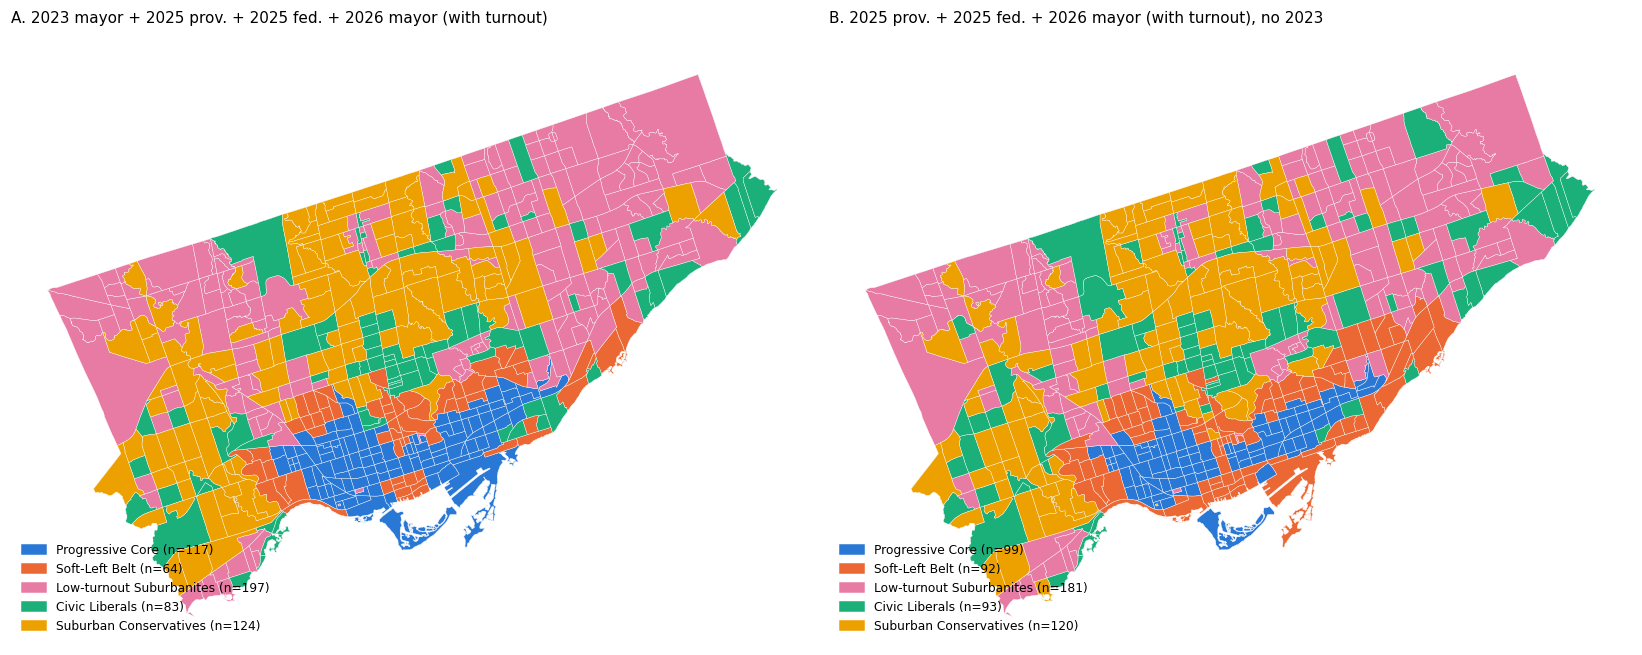

A: Model 8F group (rows) vs new group (columns)


v_a,Civic Liberals,Low-turnout Suburbanites,Progressive Core,Soft-Left Belt,Suburban Conservatives
cluster_8f,,,,,
Progressive Core,0,2,106,1,0
Soft-Left Belt,11,1,10,60,3
Civic Liberals,69,4,1,0,3
Suburban Conservatives,3,13,0,1,112
Low-turnout Suburbanites,0,177,0,2,6


B: Model 8F group (rows) vs new group (columns)


v_b,Civic Liberals,Low-turnout Suburbanites,Progressive Core,Soft-Left Belt,Suburban Conservatives
cluster_8f,,,,,
Progressive Core,0,1,98,10,0
Soft-Left Belt,6,0,0,69,10
Civic Liberals,69,3,1,2,2
Suburban Conservatives,11,15,0,2,101
Low-turnout Suburbanites,7,162,0,9,7


In [11]:
# with turnout back in, both runs recover the five Model 8F groups (see the crosstabs below), so they take the Model 8F names and colours
# (groups are ordered by pooled 2026 Chow share)
NAMES_A = NAMES_B = {0: "Progressive Core", 1: "Soft-Left Belt", 2: "Low-turnout Suburbanites", 3: "Civic Liberals", 4: "Suburban Conservatives"}
COL_A = COL_B = [CAT[0], CAT[1], CAT[4], CAT[2], CAT[3]]

fig, axes = plt.subplots(1, 2, figsize=(15, 7))
draw(axes[0], "v_a", list(range(K)), NAMES_A, COL_A, "A. 2023 mayor + 2025 prov. + 2025 fed. + 2026 mayor (with turnout)")
draw(axes[1], "v_b", list(range(K)), NAMES_B, COL_B, "B. 2025 prov. + 2025 fed. + 2026 mayor (with turnout), no 2023")
plt.tight_layout(); plt.show()

for col, names, tag in [("v_a", NAMES_A, "A"), ("v_b", NAMES_B, "B")]:
    print(f"{tag}: Model 8F group (rows) vs new group (columns)")
    display(pd.crosstab(gdf["cluster_8f"].map(OLD_NAMES), gdf[col].map(names)).reindex([OLD_NAMES[k] for k in OLD_ORDER]))

In [12]:
POL6 = POL + [("Mapped vote rate 2026", "m26_turnout", "mun_cit")]
for col, names, tag in [("v_a", NAMES_A, "A"), ("v_b", NAMES_B, "B")]:
    print(f"{tag}: pooled political profile (%)")
    display(political_table(col, range(K), names, POL6).round(1))

A: pooled political profile (%)


,Chow 2023,Bailão 2023,Mayor turnout 2023,Chow lead 2026,Chow 2026,Bradford 2026,Other 2026,Prov PC,Prov NDP,Prov Lib,Prov turnout,Fed Lib,Fed CPC,Fed NDP,Fed turnout,Mapped vote rate 2026
Progressive Core,52.7,23.2,44.8,47.2,71.8,24.7,3.5,15.9,49.9,29.8,53.5,62.7,21.1,14.2,73.8,45.6
Soft-Left Belt,39.0,32.8,43.9,17.4,57.1,39.7,3.2,24.5,37.6,34.0,50.5,61.0,28.4,8.9,74.0,43.7
Low-turnout Suburbanites,36.0,28.9,30.0,13.5,53.1,39.6,7.3,42.5,14.0,39.0,40.9,58.6,36.1,3.9,64.0,33.1
Civic Liberals,31.7,36.5,44.9,7.7,51.9,44.2,3.9,35.7,10.6,49.2,53.9,58.9,36.6,3.2,79.5,46.6
Suburban Conservatives,24.2,43.6,38.9,-20.6,37.7,58.3,4.0,47.6,7.1,40.6,45.9,51.4,45.1,2.7,68.8,38.6
Toronto,37.2,32.5,38.7,14.1,54.7,40.6,4.6,34.0,23.3,38.4,47.6,58.4,33.8,6.4,70.5,40.1


B: pooled political profile (%)


,Chow 2023,Bailão 2023,Mayor turnout 2023,Chow lead 2026,Chow 2026,Bradford 2026,Other 2026,Prov PC,Prov NDP,Prov Lib,Prov turnout,Fed Lib,Fed CPC,Fed NDP,Fed turnout,Mapped vote rate 2026
Progressive Core,53.3,22.9,45.9,48.8,72.6,23.8,3.6,15.3,51.5,28.8,54.3,62.6,20.2,15.1,74.0,46.3
Soft-Left Belt,42.2,30.0,42.1,25.3,60.9,35.6,3.4,23.1,39.3,33.6,50.2,61.8,27.1,9.2,73.2,43.0
Low-turnout Suburbanites,35.6,29.2,29.4,12.7,52.7,39.9,7.4,43.2,12.7,39.6,40.1,58.1,36.7,3.9,63.2,32.5
Civic Liberals,30.9,36.6,43.4,5.5,50.7,45.1,4.2,38.3,8.7,48.5,53.0,58.2,37.7,3.0,78.6,45.8
Suburban Conservatives,24.4,43.8,39.6,-21.4,37.4,58.8,3.9,46.9,7.7,40.9,46.3,51.7,44.9,2.6,69.0,38.8
Toronto,37.2,32.5,38.7,14.1,54.7,40.6,4.6,34.0,23.3,38.4,47.6,58.4,33.8,6.4,70.5,40.1


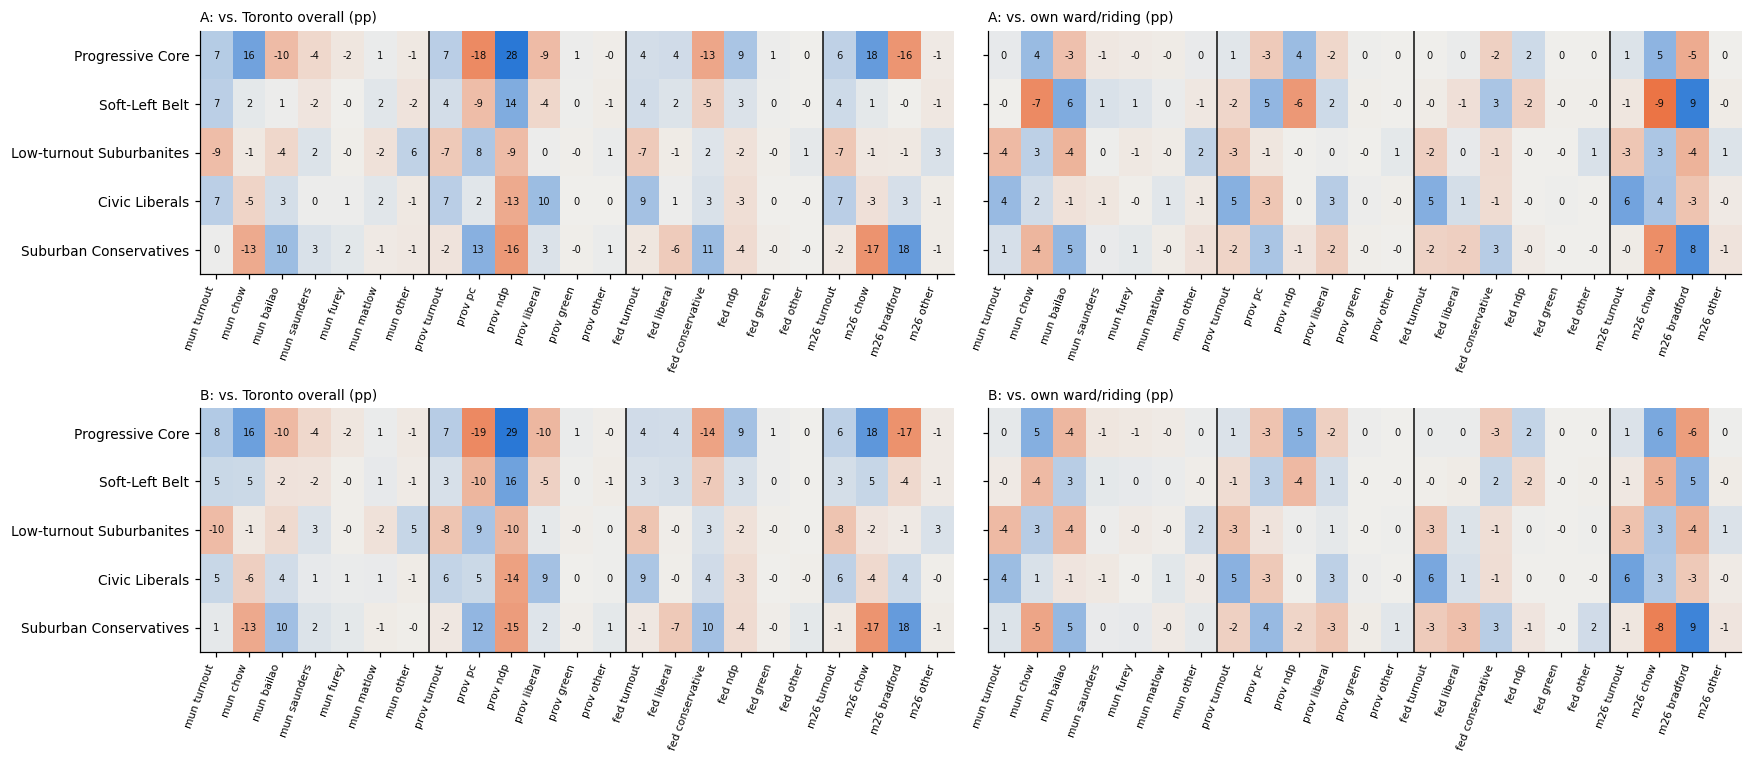

In [13]:
PROFILE6 = OLD + M26T
fig, axes = plt.subplots(2, 2, figsize=(16, 7), sharey="row")
for r, (col, names, tag) in enumerate([("v_a", NAMES_A, "A"), ("v_b", NAMES_B, "B")]):
    for ax, suffix, title, vmax in [(axes[r, 0], "_vs_city", "vs. Toronto overall (pp)", 25), (axes[r, 1], "_vs_riding", "vs. own ward/riding (pp)", 10)]:
        prof = pd.DataFrame({c: [gdf.loc[gdf[col] == k, c + suffix].mean() * 100 for k in range(K)] for c in PROFILE6}, index=[names[k] for k in range(K)])
        ax.imshow(prof.values, cmap=DIV, vmin=-vmax, vmax=vmax, aspect="auto")
        ax.set_xticks(range(len(PROFILE6)), [c.replace("_", " ") for c in PROFILE6], rotation=70, ha="right", fontsize=7); ax.set_yticks(range(K), prof.index)
        for (i, j), v in np.ndenumerate(prof.values): ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=6.5, color="#0b0b0b")
        for x in (6.5, 12.5, 18.5): ax.axvline(x, color="#0b0b0b", lw=1)
        ax.set_title(f"{tag}: {title}", loc="left", fontsize=9)
plt.tight_layout(); plt.show()

In [14]:
for col, names, tag in [("v_a", NAMES_A, "A"), ("v_b", NAMES_B, "B")]:
    print(f"{tag}: demographic profile")
    display(demo_table(col, range(K), names).round(1))

A: demographic profile


,CTs,Population,Pop share %,Density /km²,Renter households %,Apartment dwellings %,Visible minority %,Immigrants %,University degree %,Age 65+ %,Car commute %,Transit commute %,Median income ($),Avg age,Avg HH size,Shelter burden %,Recent migrants %
Progressive Core,117.0,545966.0,19.5,8932.8,58.5,74.7,42.0,35.3,49.2,13.0,41.3,29.7,45324.4,40.0,2.0,33.9,19.9
Soft-Left Belt,64.0,298518.0,10.7,6148.2,49.6,67.8,37.4,36.1,52.2,16.2,50.8,25.9,53226.2,41.5,2.1,33.1,20.7
Low-turnout Suburbanites,197.0,955565.0,34.2,3903.3,47.6,55.6,77.7,57.5,27.8,16.4,67.0,27.0,33182.5,40.8,2.8,30.7,15.2
Civic Liberals,83.0,422566.0,15.1,4602.8,45.7,68.5,48.5,43.4,48.0,18.0,62.0,26.8,47263.1,42.4,2.3,32.8,19.2
Suburban Conservatives,124.0,571741.0,20.5,3028.3,36.7,38.9,46.6,46.8,38.6,19.6,70.5,21.7,43225.2,43.3,2.7,28.0,12.6
Toronto,585.0,2794356.0,100.0,4399.9,48.1,60.6,55.7,46.6,40.0,16.6,60.9,26.2,41881.0,41.5,2.5,31.3,16.8


B: demographic profile


,CTs,Population,Pop share %,Density /km²,Renter households %,Apartment dwellings %,Visible minority %,Immigrants %,University degree %,Age 65+ %,Car commute %,Transit commute %,Median income ($),Avg age,Avg HH size,Shelter burden %,Recent migrants %
Progressive Core,99.0,424313.0,15.2,9315.8,58.3,70.2,39.9,34.5,46.6,14.0,42.0,30.6,43259.3,40.7,2.1,32.7,16.8
Soft-Left Belt,92.0,484274.0,17.3,6441.6,52.3,71.5,44.0,38.2,50.7,14.2,49.1,27.6,50239.4,40.3,2.1,33.7,22.1
Low-turnout Suburbanites,181.0,874753.0,31.3,3893.7,47.5,54.5,77.3,57.5,27.2,16.4,67.5,26.6,33052.2,40.8,2.8,30.4,14.9
Civic Liberals,93.0,475785.0,17.0,4147.4,45.3,67.7,53.0,46.0,45.5,18.0,64.0,26.3,45409.1,42.3,2.3,32.6,19.1
Suburban Conservatives,120.0,535231.0,19.2,3058.7,36.5,40.5,45.5,46.2,40.4,20.0,70.0,21.3,44520.4,43.5,2.7,28.6,12.8
Toronto,585.0,2794356.0,100.0,4399.9,48.1,60.6,55.7,46.6,40.0,16.6,60.9,26.2,41881.0,41.5,2.5,31.3,16.8


## 7. What the turnout variants show

*Pooled shares from the tables above. "Mapped vote rate" is the 2026 turnout proxy defined in section 6.*

**Adding 2026 turnout brings the Model 8F groups back.** Both variants recover groups that line up one-to-one with the five Model 8F groups, which they take their names from. The ARI against Model 8F is 0.77 for A and 0.68 for B. Against section 1's no-turnout solution it is only 0.44 and 0.46. So most of section 1's re-sorting came from giving the 2026 block shares but no participation signal.

| Group | A: CTs / pop. share | B: CTs / pop. share | Chow lead 2026 (A / B) | Mapped vote rate 2026 (A / B) |
| --- | --- | --- | --- | --- |
| Progressive Core | 117 / 19% | 99 / 15% | +47.2 / +48.8 | 45.6% / 46.3% |
| Soft-Left Belt | 64 / 11% | 92 / 17% | +17.4 / +25.3 | 43.7% / 43.0% |
| Low-turnout Suburbanites | 197 / 34% | 181 / 31% | +13.5 / +12.7 | 33.1% / 32.5% |
| Civic Liberals | 83 / 15% | 93 / 17% | +7.7 / +5.5 | 46.6% / 45.8% |
| Suburban Conservatives | 124 / 21% | 120 / 19% | −20.6 / −21.4 | 38.6% / 38.8% |

- **Civic Liberals return as a distinct group** in both variants. They have the highest federal turnout (79.5% in A, 78.6% in B) and the strongest provincial Liberal share (about 49%), and 2026 is close there (Chow +8 in A, +5 in B). The older work found this group depends most on turnout.
- **Low-turnout Suburbanites** are again the lowest on 2026 participation (about 33% vs 40% citywide) and are about 77% racialized. They still gave Chow a lead in 2026, though a smaller one than in the progressive groups.
- **Suburban Conservatives** are the Bradford group (58% to 59%), with the PC and Conservative vote high and the NDP vote under 8%.
- **B (no 2023 data) is a close cousin of A.** The ARI between them is 0.77. Dropping 2023 mostly moves the Soft-Left Belt/Progressive Core boundary, so the Soft-Left Belt is 64 tracts in A and 92 in B (85 in Model 8F), and shifts some tracts between the Civic Liberals and Suburban Conservatives. The 2025 provincial and federal results plus 2026 are enough to rebuild nearly the same neighbourhood types.

**Caveats.** The 2026 turnout variable is a mapped-vote proxy, so differences in it partly reflect which polling subdivisions had polygons. It correlates 0.86 with 2023 turnout across tracts, which suggests it is capturing real participation differences, but it is not an official rate. As above, there are no k-sweeps or stability checks here.